> **Revision (November 2026).** Re-run end to end on the local SQL result files, with three changes to the weather test:
> 1. **Identical ride rows are kept.** Start times in result 7 are rounded to the hour, so two different rides that
>    started in the same hour with the same duration produce identical rows. They are most likely separate rides.
> 2. **Welch's t-test** (no equal-variance assumption) replaces the standard t-test, and the 6 rides lasting 0 seconds
>    (recording errors) are excluded.
> 3. **A same-hour comparison** is added: rainy rides happen mostly in the afternoon, when the drive is slowest anyway,
>    so part of the raw difference is the time of day. A regression with one term per start hour isolates the effect of
>    the weather. A conclusion section is added at the end.

In [1]:
# importing libraries for data manipulation
import pandas as pd
import numpy as np
# importing libraries for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

#Loading Dataset


In [2]:
# Results of the SQL queries, saved as CSV files in this project folder
result1 = pd.read_csv('moved_project_sql_result_01.csv')
result4 = pd.read_csv('moved_project_sql_result_04.csv')
result7 = pd.read_csv('moved_project_sql_result_07.csv')

#Data Overview#



## Result 1 Dataframe Assessing and cleaning

##Data Assessment result1

In [3]:
result1.head()

,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasin,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [4]:
result1.shape

(64, 2)

In [5]:
result1.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   company_name  64 non-null     str  
 1   trips_amount  64 non-null     int64
dtypes: int64(1), str(1)
memory usage: 1.1 KB


In [6]:
result1.duplicated().sum()

np.int64(0)

In [7]:
result1.isna().sum()

company_name    0
trips_amount    0
dtype: int64

In [8]:
result1.describe()

,trips_amount
count,64.000000
mean,2145.484375
std,3812.310186
min,2.000000
25%,20.750000
50%,178.500000
75%,2106.500000
max,19558.000000


In [9]:
result1['trips_amount'].median()

np.float64(178.5)

<Axes: xlabel='trips_amount'>

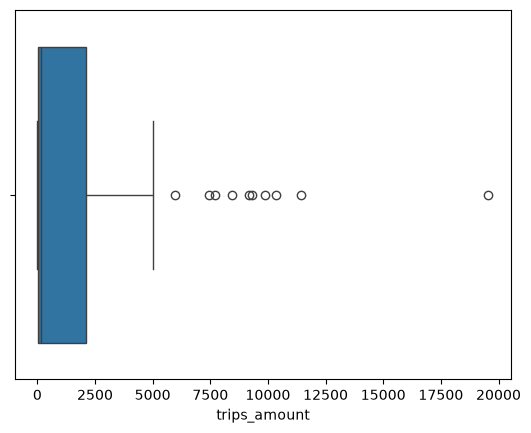

In [10]:
#visualising outliers
sns.boxplot(x=result1['trips_amount'])

In [11]:
# for unique company name count
unique_company_name_count_result1 = result1['company_name'].nunique()
display("Number of unique companies result1:", unique_company_name_count_result1)

'Number of unique companies result1:'

64

**Feature information in Result1**
- Company Name is basically taxi company
- Number of rides for the taxi company in November
- Data types are correct
- no null values
- no duplicated entries
- median of ca 178 while mean is ca 2145. There are outliers in the data set. Thats why we will prefer median as centrality of data

## Result 4 Dataframe Assessing and cleaning

In [12]:
result4.head(10)

,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000
5,Lake View,2420.966667
6,Grant Park,2068.533333
7,Museum Campus,1510.000000
8,Gold Coast,1364.233333
9,Sheffield & DePaul,1259.766667


In [13]:
result4.shape

(94, 2)

In [14]:
result4.info()

<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     str    
 1   average_trips          94 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.6 KB


In [15]:
result4['average_trips'] = result4['average_trips'].astype(int)
result4

,dropoff_location_name,average_trips
0,Loop,10727
1,River North,9523
2,Streeterville,6664
3,West Loop,5163
4,O'Hare,2546
...,...,...
89,Mount Greenwood,3
90,Hegewisch,3
91,Burnside,2
92,East Side,1


In [16]:
result4['dropoff_location_name'].nunique()

94

In [17]:
result4.duplicated().sum()

np.int64(0)

In [18]:
result4.isna().sum()

dropoff_location_name    0
average_trips            0
dtype: int64

In [19]:
result4.describe()

,average_trips
count,94.000000
mean,599.478723
std,1714.555974
min,1.000000
25%,14.000000
50%,51.500000
75%,298.750000
max,10727.000000


In [20]:
result4['average_trips'].median()

np.float64(51.5)

<Axes: xlabel='average_trips'>

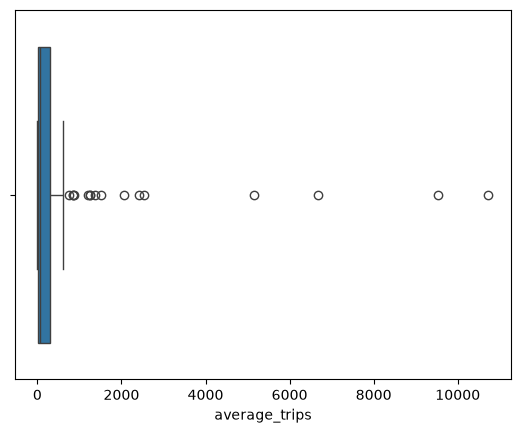

In [21]:
#visualising outliers
sns.boxplot(x=result4['average_trips'])

In [22]:
# for unique drop off location count
unique_drop_off_loc_count_result4 = result4['dropoff_location_name'].nunique()
display("Number of unique drop off locations result 4:", unique_drop_off_loc_count_result4)

'Number of unique drop off locations result 4:'

94

**Feature information in Result4**

- dropoff_location_name is the chicago neighbourhood where the ride ended.
- average_trips is the avg no of rides that ended in each neighbourhood
- median of av trips to locations is 52 while mean is 599 and max is 10727. Probably there are outliers in the data set because some locations are extremely popular in comparison to others

## Result 7 Dataframe Assessing and Cleaning

In [23]:
result7.head()

,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


In [24]:
result7.shape

(1068, 3)

In [25]:
result7['weather_conditions'].nunique()

2

In [26]:
result7['weather_conditions'].unique()

<StringArray>
['Good', 'Bad']
Length: 2, dtype: str

In [27]:
result7.info()

<class 'pandas.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   str    
 1   weather_conditions  1068 non-null   str    
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), str(2)
memory usage: 25.2 KB


In [28]:
# I can see with info if I have null values. Is it good practice to still run isna?
result7.isna().sum()

start_ts              0
weather_conditions    0
duration_seconds      0
dtype: int64

In [29]:
result7['duration_minutes'] = result7['duration_seconds']/60
result7

,start_ts,weather_conditions,duration_seconds,duration_minutes
0,2017-11-25 16:00:00,Good,2410.0,40.166667
1,2017-11-25 14:00:00,Good,1920.0,32.000000
2,2017-11-25 12:00:00,Good,1543.0,25.716667
3,2017-11-04 10:00:00,Good,2512.0,41.866667
4,2017-11-11 07:00:00,Good,1440.0,24.000000
...,...,...,...,...
1063,2017-11-25 11:00:00,Good,0.0,0.000000
1064,2017-11-11 10:00:00,Good,1318.0,21.966667
1065,2017-11-11 13:00:00,Good,2100.0,35.000000
1066,2017-11-11 08:00:00,Good,1380.0,23.000000


In [30]:
result7.duplicated().sum()

np.int64(197)

In [31]:
# Find and display duplicated rows in the DataFrame
# I am not really sure if I can spot a possible reason though as to why they are dupicated?
duplicated_rows_result7 = result7[result7.duplicated(keep=False)]

print("Duplicated Rows result7:")
display(duplicated_rows_result7)

Duplicated Rows result7:


,start_ts,weather_conditions,duration_seconds,duration_minutes
4,2017-11-11 07:00:00,Good,1440.0,24.0
8,2017-11-11 14:00:00,Good,2460.0,41.0
10,2017-11-18 06:00:00,Good,1500.0,25.0
16,2017-11-04 12:00:00,Good,2640.0,44.0
23,2017-11-04 14:00:00,Good,3360.0,56.0
...,...,...,...,...
1054,2017-11-11 07:00:00,Good,1380.0,23.0
1058,2017-11-25 12:00:00,Good,1440.0,24.0
1062,2017-11-11 06:00:00,Good,1500.0,25.0
1065,2017-11-11 13:00:00,Good,2100.0,35.0


In [32]:
# Why are rows duplicated? Start times are rounded to the hour:
print('Rides:', len(result7))
print('Distinct start times:', result7['start_ts'].nunique())
print('Minutes in start times:', sorted(pd.to_datetime(result7['start_ts']).dt.minute.unique()))
# With only about 80 distinct start hours for over 1,000 rides, two different rides can easily share the same
# start hour, weather and duration. The identical rows are therefore kept as separate rides.

Rides: 1068
Distinct start times: 81
Minutes in start times: [np.int32(0)]


In [33]:
result7['duration_seconds'].median()

np.float64(1980.0)

<Axes: >

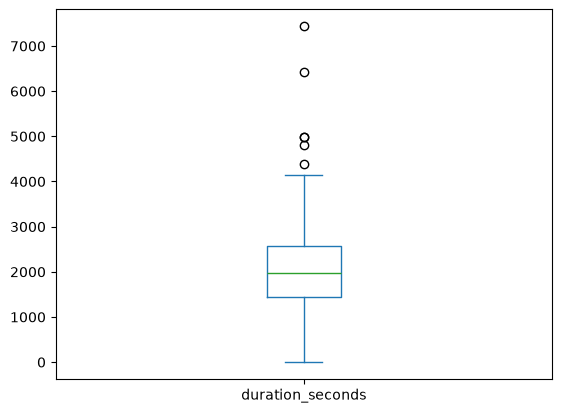

In [34]:
result7['duration_seconds'].plot(kind='box')

In [35]:
result7.describe()

,duration_seconds,duration_minutes
count,1068.000000,1068.000000
mean,2071.731273,34.528855
std,769.461125,12.824352
min,0.000000,0.000000
25%,1438.250000,23.970833
50%,1980.000000,33.000000
75%,2580.000000,43.000000
max,7440.000000,124.000000


In [36]:
# Convert the 'start_ts' column to a datetime object
result7['start_ts'] = pd.to_datetime(result7['start_ts'])
result7

,start_ts,weather_conditions,duration_seconds,duration_minutes
0,2017-11-25 16:00:00,Good,2410.0,40.166667
1,2017-11-25 14:00:00,Good,1920.0,32.000000
2,2017-11-25 12:00:00,Good,1543.0,25.716667
3,2017-11-04 10:00:00,Good,2512.0,41.866667
4,2017-11-11 07:00:00,Good,1440.0,24.000000
...,...,...,...,...
1063,2017-11-25 11:00:00,Good,0.0,0.000000
1064,2017-11-11 10:00:00,Good,1318.0,21.966667
1065,2017-11-11 13:00:00,Good,2100.0,35.000000
1066,2017-11-11 08:00:00,Good,1380.0,23.000000


In [37]:
# to_timedelta this function simply converts the time in numeric format to time format
result7['closing_time'] = result7['start_ts'] + pd.to_timedelta(result7['duration_seconds'], unit='s')
result7

,start_ts,weather_conditions,duration_seconds,duration_minutes,closing_time
0,2017-11-25 16:00:00,Good,2410.0,40.166667,2017-11-25 16:40:10
1,2017-11-25 14:00:00,Good,1920.0,32.000000,2017-11-25 14:32:00
2,2017-11-25 12:00:00,Good,1543.0,25.716667,2017-11-25 12:25:43
3,2017-11-04 10:00:00,Good,2512.0,41.866667,2017-11-04 10:41:52
4,2017-11-11 07:00:00,Good,1440.0,24.000000,2017-11-11 07:24:00
...,...,...,...,...,...
1063,2017-11-25 11:00:00,Good,0.0,0.000000,2017-11-25 11:00:00
1064,2017-11-11 10:00:00,Good,1318.0,21.966667,2017-11-11 10:21:58
1065,2017-11-11 13:00:00,Good,2100.0,35.000000,2017-11-11 13:35:00
1066,2017-11-11 08:00:00,Good,1380.0,23.000000,2017-11-11 08:23:00


**Feature information in Result7**

- Dataset contains data on rides from the Loop to O'Hare International Airport on Saturdays in November 2017.
- 197 rows are identical to another row, but start times are rounded to the hour, so these are most likely separate
  rides with the same start hour, weather and duration. They are kept.
- start ts data type is object but it should be date time. Converted to datetime.



---



---



##Data Anaysis




## 1. identify the top 10 neighborhoods in terms of drop-offs

In [38]:
result4

,dropoff_location_name,average_trips
0,Loop,10727
1,River North,9523
2,Streeterville,6664
3,West Loop,5163
4,O'Hare,2546
...,...,...
89,Mount Greenwood,3
90,Hegewisch,3
91,Burnside,2
92,East Side,1


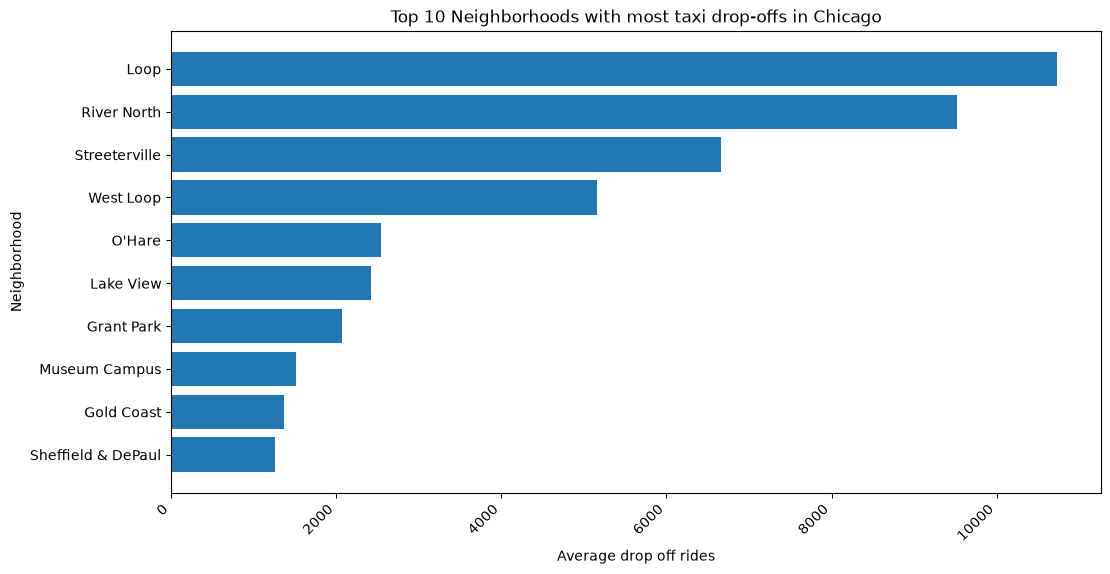

In [39]:
plt.figure(figsize=(12, 6))
top_10_dropoff_loc = result4.head(10)
plt.barh(top_10_dropoff_loc['dropoff_location_name'], top_10_dropoff_loc['average_trips'])

# Create a bar plot for the top 10 neighborhoods in terms of drop offs
plt.title('Top 10 Neighborhoods with most taxi drop-offs in Chicago')
plt.xlabel('Average drop off rides')
plt.ylabel('Neighborhood')
plt.xticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.show()

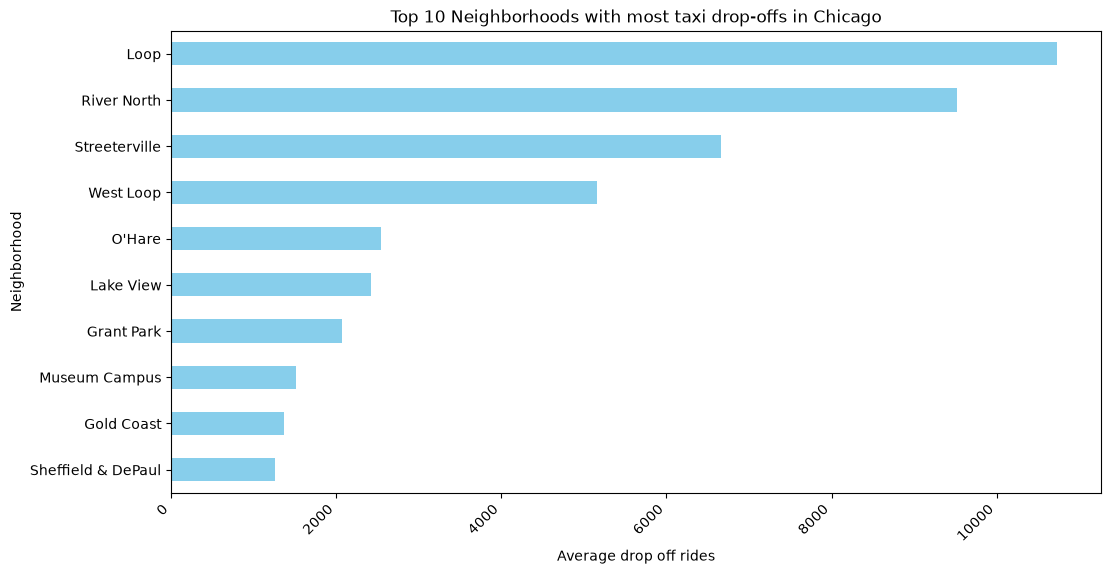

In [40]:
# in pandas plot function the data has to be provided in the form of pandas series
top_10_neighborhoods = result4.groupby('dropoff_location_name')
top_10_neighborhoods_sorted = top_10_neighborhoods['average_trips'].mean().sort_values(ascending=False).head(10)

# Create a bar plot for the top 10 neighborhoods in terms of drop offs
plt.figure(figsize=(12, 6))
top_10_neighborhoods_sorted.plot(kind='barh', color='skyblue')
plt.title('Top 10 Neighborhoods with most taxi drop-offs in Chicago')
plt.xlabel('Average drop off rides')
plt.ylabel('Neighborhood')
plt.xticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.show()

## 2. Top 10 Taxi Companies by number of rides

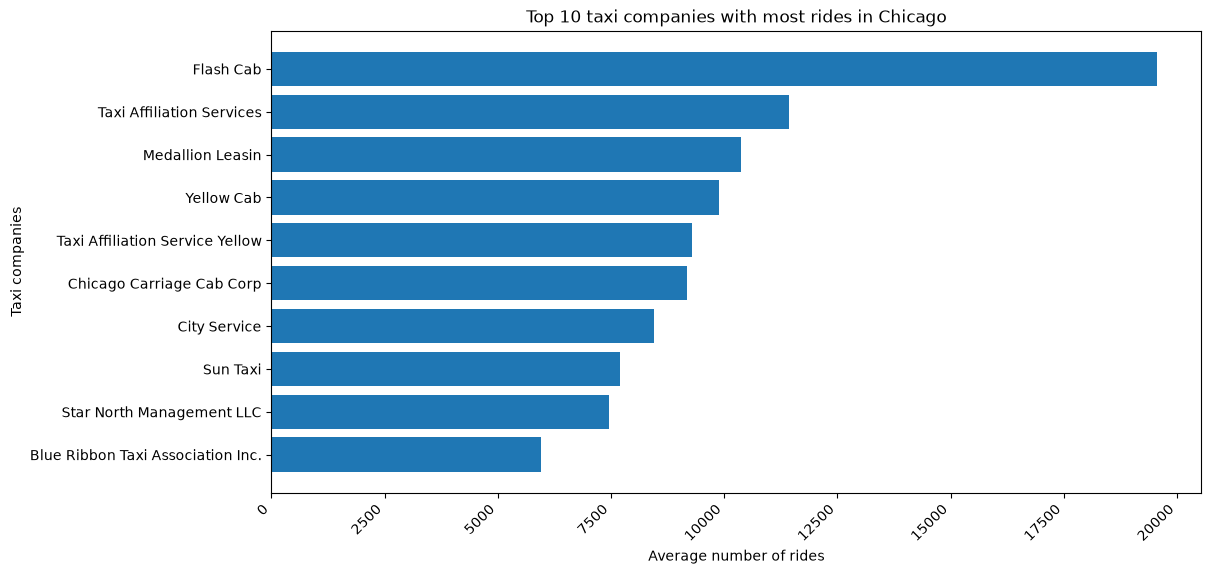

In [41]:
top_10_taxi_comp = result1.head(10)
plt.figure(figsize=(12, 6))
plt.barh(top_10_taxi_comp['company_name'], top_10_taxi_comp['trips_amount'])

# Create a bar plot for the top 10 taxi companies in terms of number of rides
plt.title('Top 10 taxi companies with most rides in Chicago')
plt.xlabel('Average number of rides')
plt.ylabel('Taxi companies')
plt.xticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.show()

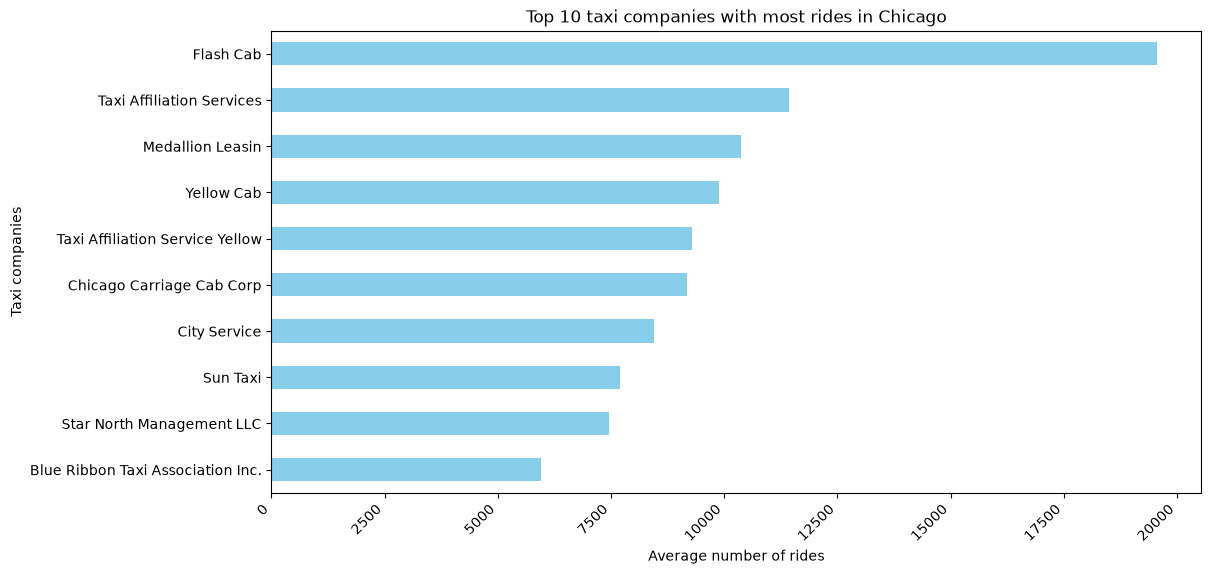

In [42]:
top_10_taxi_companies = result1.groupby('company_name')
top_10_taxi_companies_sorted = top_10_taxi_companies['trips_amount'].mean().sort_values(ascending=False).head(10)

# Create a bar plot for the top 10 taxi companies in terms of number of rides
plt.figure(figsize=(12, 6))
top_10_taxi_companies_sorted.plot(kind='barh', color='skyblue')
plt.title('Top 10 taxi companies with most rides in Chicago')
plt.xlabel('Average number of rides')
plt.ylabel('Taxi companies')
plt.xticks(rotation=45, ha='right')
plt.gca().invert_yaxis()
plt.show()



---



---



#Testing hypotheses


## Does the average duration of rides from the Loop to O'Hare International Airport changes on rainy Saturdays.

**Null Hypothesis (H0):**

The average duration of rides from the Loop to O'Hare International Airport on rainy Saturdays is the same as the average duration on non-rainy Saturdays.

**Alternative Hypothesis (H1):**

The average duration of rides from the Loop to O'Hare International Airport on rainy Saturdays is different from the average duration on non-rainy Saturdays.

**Criteria for Testing the Hypotheses:**

**Data Selection:**
 Separate the data into two groups based on weather conditions (rainy and non-rainy Saturdays).

**Significance Level (Alpha):** Typically, a significance level of 0.05 (5%) is commonly used.

**Statistical Test:**
Use a two-sample t-test to compare the means of the two groups (rainy vs. non-rainy Saturdays). The t-test helps to determine if the means of two groups are significantly different.

In [43]:
result7.info()

<class 'pandas.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[us]
 1   weather_conditions  1068 non-null   str           
 2   duration_seconds    1068 non-null   float64       
 3   duration_minutes    1068 non-null   float64       
 4   closing_time        1068 non-null   datetime64[us]
dtypes: datetime64[us](2), float64(2), str(1)
memory usage: 41.8 KB


In [44]:
# add name of week day
result7['day_name'] = result7['start_ts'].dt.day_name()
display(result7)

,start_ts,weather_conditions,duration_seconds,duration_minutes,closing_time,day_name
0,2017-11-25 16:00:00,Good,2410.0,40.166667,2017-11-25 16:40:10,Saturday
1,2017-11-25 14:00:00,Good,1920.0,32.000000,2017-11-25 14:32:00,Saturday
2,2017-11-25 12:00:00,Good,1543.0,25.716667,2017-11-25 12:25:43,Saturday
3,2017-11-04 10:00:00,Good,2512.0,41.866667,2017-11-04 10:41:52,Saturday
4,2017-11-11 07:00:00,Good,1440.0,24.000000,2017-11-11 07:24:00,Saturday
...,...,...,...,...,...,...
1063,2017-11-25 11:00:00,Good,0.0,0.000000,2017-11-25 11:00:00,Saturday
1064,2017-11-11 10:00:00,Good,1318.0,21.966667,2017-11-11 10:21:58,Saturday
1065,2017-11-11 13:00:00,Good,2100.0,35.000000,2017-11-11 13:35:00,Saturday
1066,2017-11-11 08:00:00,Good,1380.0,23.000000,2017-11-11 08:23:00,Saturday


In [45]:
result7_good_weather = result7[result7['weather_conditions'] == 'Good']
result7_bad_weather = result7[result7['weather_conditions'] == 'Bad']
display(result7_good_weather)
display(result7_bad_weather)

,start_ts,weather_conditions,duration_seconds,duration_minutes,closing_time,day_name
0,2017-11-25 16:00:00,Good,2410.0,40.166667,2017-11-25 16:40:10,Saturday
1,2017-11-25 14:00:00,Good,1920.0,32.000000,2017-11-25 14:32:00,Saturday
2,2017-11-25 12:00:00,Good,1543.0,25.716667,2017-11-25 12:25:43,Saturday
3,2017-11-04 10:00:00,Good,2512.0,41.866667,2017-11-04 10:41:52,Saturday
4,2017-11-11 07:00:00,Good,1440.0,24.000000,2017-11-11 07:24:00,Saturday
...,...,...,...,...,...,...
1062,2017-11-11 06:00:00,Good,1500.0,25.000000,2017-11-11 06:25:00,Saturday
1063,2017-11-25 11:00:00,Good,0.0,0.000000,2017-11-25 11:00:00,Saturday
1064,2017-11-11 10:00:00,Good,1318.0,21.966667,2017-11-11 10:21:58,Saturday
1065,2017-11-11 13:00:00,Good,2100.0,35.000000,2017-11-11 13:35:00,Saturday


,start_ts,weather_conditions,duration_seconds,duration_minutes,closing_time,day_name
6,2017-11-04 16:00:00,Bad,2969.0,49.483333,2017-11-04 16:49:29,Saturday
30,2017-11-18 12:00:00,Bad,1980.0,33.000000,2017-11-18 12:33:00,Saturday
34,2017-11-04 17:00:00,Bad,2460.0,41.000000,2017-11-04 17:41:00,Saturday
51,2017-11-04 16:00:00,Bad,2760.0,46.000000,2017-11-04 16:46:00,Saturday
52,2017-11-18 12:00:00,Bad,2460.0,41.000000,2017-11-18 12:41:00,Saturday
...,...,...,...,...,...,...
1031,2017-11-18 12:00:00,Bad,2560.0,42.666667,2017-11-18 12:42:40,Saturday
1032,2017-11-18 10:00:00,Bad,1908.0,31.800000,2017-11-18 10:31:48,Saturday
1053,2017-11-18 12:00:00,Bad,2400.0,40.000000,2017-11-18 12:40:00,Saturday
1061,2017-11-18 16:00:00,Bad,2186.0,36.433333,2017-11-18 16:36:26,Saturday


In [46]:
import scipy.stats as stats

# Rides of 0 seconds are recording errors
rides = result7[result7['duration_seconds'] > 0].copy()
rides['duration_minutes'] = rides['duration_seconds'] / 60
result7_good_weather = rides[rides['weather_conditions'] == 'Good']
result7_bad_weather = rides[rides['weather_conditions'] == 'Bad']

# Welch's t-test: does not assume the two groups have the same variance
t_statistic, p_value = stats.ttest_ind(result7_bad_weather['duration_minutes'], result7_good_weather['duration_minutes'],
                                       equal_var=False)

alpha = 0.05

print(f"Average duration, good weather: {result7_good_weather['duration_minutes'].mean():.1f} min ({len(result7_good_weather)} rides)")
print(f"Average duration, bad weather:  {result7_bad_weather['duration_minutes'].mean():.1f} min ({len(result7_bad_weather)} rides)")
print(f't-statistic: {t_statistic}')
print(f'p-value: {p_value}')

if p_value < alpha:
    print('Reject the null hypothesis. The average duration of rides from the Loop to OHare International Airport on rainy Saturdays is not the same as the average duration on non-rainy Saturdays')
else:
    print('Fail to reject the null hypothesis')

Average duration, good weather: 33.6 min (882 rides)
Average duration, bad weather:  40.5 min (180 rides)
t-statistic: 6.97932883593079
p-value: 2.4173590471585587e-11
Reject the null hypothesis. The average duration of rides from the Loop to OHare International Airport on rainy Saturdays is not the same as the average duration on non-rainy Saturdays


### Is it the rain, or the time of day?

Rides take longer in the afternoon whatever the weather. If rainy rides happen mostly in the afternoon, the raw
comparison mixes the two effects.

In [47]:
rides['hour'] = rides['start_ts'].dt.hour
afternoon = rides.groupby('weather_conditions')['hour'].apply(lambda h: h.between(12, 17).mean())
print('Share of rides starting 12:00-17:59:')
print(afternoon.round(2))
print()
print('Average duration (minutes) by start hour:')
print(rides.groupby('hour')['duration_minutes'].mean().round(1).to_string())

Share of rides starting 12:00-17:59:
weather_conditions
Bad     0.64
Good    0.40
Name: hour, dtype: float64

Average duration (minutes) by start hour:
hour
0     17.0
2     49.3
3     20.8
4     22.7
5     23.4
6     24.2
7     22.8
8     23.4
9     24.9
10    28.6
11    34.9
12    39.4
13    43.3
14    48.5
15    48.1
16    45.4
17    40.2
18    40.6
19    33.2
20    31.4
21    28.4
22    23.0
23    24.3


- About two thirds of rainy rides started between noon and 6 pm, against about 40% of dry rides, and midday rides are
  the slowest. Comparing rides that started **at the same hour** separates the weather from the time of day.

In [48]:
# Regression: duration ~ bad weather + one dummy variable per start hour
bad = (rides['weather_conditions'] == 'Bad').astype(float)
hour_dummies = pd.get_dummies(rides['hour'], prefix='h', drop_first=True).astype(float)
X = np.column_stack([np.ones(len(rides)), bad.values, hour_dummies.values])
y = rides['duration_minutes'].values
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ beta
dof = len(y) - X.shape[1]
cov = (resid @ resid / dof) * np.linalg.pinv(X.T @ X)
se = np.sqrt(cov[1, 1])
t_same_hour = beta[1] / se
p_same_hour = 2 * stats.t.sf(abs(t_same_hour), dof)
ci = stats.t.ppf(0.975, dof) * se
print(f'Effect of bad weather at the same start hour: {beta[1]:+.1f} minutes '
      f'(95% CI {beta[1] - ci:+.1f} to {beta[1] + ci:+.1f}), p-value {p_same_hour:.2g}')
raw_gap = result7_bad_weather['duration_minutes'].mean() - result7_good_weather['duration_minutes'].mean()
print(f'Raw difference: {raw_gap:+.1f} minutes, so about {1 - beta[1] / raw_gap:.0%} of it was the time of day')

Effect of bad weather at the same start hour: +4.3 minutes (95% CI +2.8 to +5.8), p-value 3.1e-08
Raw difference: +6.9 minutes, so about 38% of it was the time of day


In [49]:
# Robustness: the same tests with the identical rows removed
dedup = rides.drop_duplicates(subset=['start_ts', 'weather_conditions', 'duration_seconds'])
print(stats.ttest_ind(dedup.loc[dedup['weather_conditions'] == 'Bad', 'duration_minutes'],
                      dedup.loc[dedup['weather_conditions'] == 'Good', 'duration_minutes'], equal_var=False))

TtestResult(statistic=np.float64(5.3022889297470295), pvalue=np.float64(2.859195727873465e-07), df=np.float64(212.5226368850631))


#Conclusion

**Taxi companies.** Flash Cab is the clear leader (19,558 trips, about 14% of all trips), followed by Taxi Affiliation
Services and Medallion Leasing. The top 10 of 64 companies run about 72% of trips, yet no single company dominates:
the market is not highly concentrated, which leaves room for a new entrant.

**Drop-off neighbourhoods.** Rides end overwhelmingly in the centre: the Loop, River North, Streeterville and West
Loop. O'Hare airport is the fifth most common destination, the only one in the top five outside downtown.

**Weather and the airport run.** Rides from the Loop to O'Hare on Saturdays take longer in bad weather. The raw
difference is about 7 minutes (p < 0.001), but rainy rides are concentrated in the slow afternoon hours. Compared at
the same start hour, bad weather adds about **4 minutes** (95% CI roughly 3 to 6 minutes), still highly significant.
The conclusion holds with or without the identical rows. We reject the null hypothesis: the average duration of
rides from the Loop to O'Hare changes on rainy Saturdays.